# 02 · Model Application
**Train, compare, explain, save and reload XGBoost and a PyTorch MLP.**

Run after `Preprocessing.ipynb`. Set `RETRAIN=False` in section 2 to use the included trained models immediately without rerunning EDA or preparation. All implementation code is included below.

Our task is regression of the source-defined `CCME_Values` index. We deliberately avoid mixing classification standards or treating a derived index as an independent outcome.

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Imports, model definitions and evaluation functions

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / "Datasets").is_dir() else Path.cwd().parent
if not (ROOT / "Datasets").is_dir():
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
DATA = ROOT / "Datasets"
WORK = DATA / "_working"  # Local intermediate files; ignored by Git.
FIGURES = ROOT / "figures"
WORK.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
CSV = WORK / "Combined_dataset.csv"
import copy, random, platform, time, shutil
from datetime import UTC, datetime
from importlib.metadata import version
import joblib
import torch
from torch import nn
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor, DMatrix
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = [
    "Ammonia",
    "BOD",
    "Dissolved oxygen",
    "Orthophosphate",
    "pH",
    "Temperature",
    "Nitrogen",
    "Nitrate",
]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    Missing/nonfinite values produce NaN rather than silently passing a test.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result

def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for unit/measurement review, not converted.
    Every input gets a fixed missing/invalid flag, even if train has no missingness.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)

def sample(frame, cap, seed):
    if cap and len(frame) > cap:
        return frame.sample(n=cap, random_state=seed).sort_index()
    return frame

def seed_everything(seed, threads=4):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)

class MLP(nn.Module):
    def __init__(self, input_dim=16, widths=(64, 32), dropout=0.1):
        super().__init__()
        layers = []
        size = input_dim
        for width in widths:
            layers.extend([nn.Linear(size, width), nn.ReLU(), nn.Dropout(dropout)])
            size = width
        layers.append(nn.Linear(size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x).squeeze(-1)

def predict_mlp(model, x, batch_size=16384):
    model.eval()
    out = []
    with torch.inference_mode():
        for start in range(0, len(x), batch_size):
            batch = torch.as_tensor(np.asarray(x[start : start + batch_size]), dtype=torch.float32)
            out.append(model(batch).numpy() * 100)
    return np.clip(np.concatenate(out), 0, 100)

def fit_mlp(x, y, xv, yv, widths, config):
    seed_everything(config["seed"], config["threads"])
    model = MLP(x.shape[1], widths)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
    tx = torch.as_tensor(np.asarray(x), dtype=torch.float32)
    ty = torch.as_tensor(np.asarray(y) / 100, dtype=torch.float32)
    best_score, best_state, waiting = float("inf"), None, 0
    history = []
    for epoch in range(config["mlp_epochs"]):
        model.train()
        order = torch.randperm(len(tx))
        total = 0.0
        for ids in order.split(config["batch_size"]):
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(model(tx[ids]), ty[ids])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(ids)
        prediction = predict_mlp(model, xv)
        score = float(np.sqrt(np.mean((prediction - np.asarray(yv)) ** 2)))
        history.append(
            {
                "epoch": epoch + 1,
                "train_rmse": np.sqrt(total / len(tx)) * 100,
                "validation_rmse": score,
            }
        )
        if score < best_score - 0.0001:
            best_score, best_state, waiting = score, copy.deepcopy(model.state_dict()), 0
        else:
            waiting += 1
        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"  MLP {widths}, epoch {epoch + 1}: validation RMSE {score:.4f}", flush=True)
        if waiting >= config["mlp_patience"]:
            break
    model.load_state_dict(best_state)
    model.eval()
    return model, history

def metrics(y, prediction):
    return {
        "mae": float(mean_absolute_error(y, prediction)),
        "rmse": float(np.sqrt(mean_squared_error(y, prediction))),
        "r2": float(r2_score(y, prediction)),
    }

def residual_quantile(y, prediction, alpha=0.1):
    if not 0 < alpha < 1:
        raise ValueError("alpha must be in (0, 1)")
    residual = np.abs(np.asarray(y) - np.asarray(prediction))
    if not len(residual) or not np.isfinite(residual).all():
        raise ValueError("Calibration requires finite observations")
    rank = int(np.ceil((len(residual) + 1) * (1 - alpha)))
    if rank > len(residual):
        return float("inf")
    return float(np.partition(residual, rank - 1)[rank - 1])

def intervals(prediction, radius):
    return np.clip(prediction - radius, 0, 100), np.clip(prediction + radius, 0, 100)

def interval_metrics(y, prediction, radius):
    lower, upper = intervals(prediction, radius)
    return {
        "coverage": float(np.mean((y >= lower) & (y <= upper))),
        "mean_width": float(np.mean(upper - lower)),
        "radius": radius,
    }

def dump_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")

## 2. Load prepared inputs or the delivered trained models
Training uses the shared seed-42 sample. Two XGBoost depths and two MLP widths form a bounded validation search. Neither family sees calibration or test rows during fitting. CPU threads are fixed at four.

The supplied archive contains model weights, training-fitted preprocessors, all test predictions, metrics, training histories, feature explanations and provenance. Python/joblib files should be loaded only from this project or other trusted sources.

In [2]:
# True: reproduce training after running the first two notebooks.
# False: inspect included results and predict with pretrained models immediately.
RETRAIN = True
out, artifacts = WORK / "Results", WORK / "Models"
out.mkdir(exist_ok=True)
artifacts.mkdir(exist_ok=True)
archive = DATA / "water_quality_project_outputs.zip"
if RETRAIN:
    bundle = joblib.load(WORK / "prepared.joblib")
    config = bundle["config"]
    train, tuning, splits = bundle["train"], bundle["tuning"], bundle["splits"]
    audit, manifest = bundle["audit"], bundle["manifest"]
    tree_pre, neural_pre = bundle["tree_pre"], bundle["neural_pre"]
    xt, xvt, xn, xvn = [bundle[k] for k in ["xt", "xvt", "xn", "xvn"]]
    y, yv = bundle["y"], bundle["yv"]
    start = time.perf_counter()
    seed_everything(config["seed"], config["threads"])
else:
    # Only load the project-provided archive, because joblib uses pickle.
    with zipfile.ZipFile(archive) as z:
        for entry in z.infolist():
            target = (WORK / entry.filename).resolve()
            if not target.is_relative_to(WORK.resolve()):
                raise ValueError("Unsafe archive member")
        z.extractall(WORK)
    print("Loaded the included trained models and measured results.")

## 3. XGBoost: strong tabular baseline
Boosted trees handle thresholds and interactions without input scaling. Histogram trees, depth control, row subsampling, L2 regularization and validation early stopping constrain fitting. We compare depths 4 and 6, up to 1,000 rounds, learning rate 0.05 and patience 40.

In [3]:
if RETRAIN:
    candidates, histories = [], {}
    best_xgb, best_mlp = None, None
    best_xgb_score, best_mlp_score = float("inf"), float("inf")
    for depth in config["xgb_depths"]:
        print(f"Training XGBoost, depth {depth}...", flush=True)
        tick = time.perf_counter()
        model = XGBRegressor(
            n_estimators=config["xgb_estimators"],
            max_depth=depth,
            learning_rate=0.05,
            min_child_weight=5,
            subsample=0.9,
            colsample_bytree=1.0,
            reg_lambda=5,
            tree_method="hist",
            max_bin=256,
            objective="reg:squarederror",
            eval_metric="rmse",
            early_stopping_rounds=40,
            random_state=config["seed"],
            n_jobs=config["threads"],
        )
        model.fit(xt, y, eval_set=[(xvt, yv)], verbose=100)
        score = metrics(yv, np.clip(model.predict(xvt), 0, 100))
        candidates.append(
            {
                "family": "XGBoost",
                "architecture": str(depth),
                **score,
                "seconds": time.perf_counter() - tick,
                "best_step": int(model.best_iteration + 1),
            }
        )
        histories[f"XGBoost_depth_{depth}"] = model.evals_result()["validation_0"]["rmse"]
        if score["rmse"] < best_xgb_score:
            best_xgb, best_xgb_score = model, score["rmse"]

Training XGBoost, depth 4...
[0]	validation_0-rmse:12.86652
[100]	validation_0-rmse:0.77577
[200]	validation_0-rmse:0.56825
[300]	validation_0-rmse:0.53087
[400]	validation_0-rmse:0.51035
[500]	validation_0-rmse:0.50095
[600]	validation_0-rmse:0.49519
[700]	validation_0-rmse:0.48928
[800]	validation_0-rmse:0.48454
[900]	validation_0-rmse:0.48125
[999]	validation_0-rmse:0.47815
Training XGBoost, depth 6...
[0]	validation_0-rmse:12.83557
[100]	validation_0-rmse:0.55721
[200]	validation_0-rmse:0.47595
[300]	validation_0-rmse:0.46411
[400]	validation_0-rmse:0.45879
[500]	validation_0-rmse:0.45613
[600]	validation_0-rmse:0.45468
[700]	validation_0-rmse:0.45390
[800]	validation_0-rmse:0.45282
[842]	validation_0-rmse:0.45299


## 4. MLP: learned nonlinear interactions
A compact feedforward network uses 16 inputs, hidden widths 64/32 or 128/64, ReLU, dropout 0.1 and one linear regression output. AdamW uses learning rate 0.001 and weight decay 0.0001. MSE operates on targets divided by 100. Batch size is 2,048, at most 60 epochs, patience 10. The checkpoint minimizes validation RMSE. Predictions are clipped to [0,100].

In [4]:
if RETRAIN:
    for widths in config["mlp_widths"]:
        print(f"Training MLP {widths}...", flush=True)
        tick = time.perf_counter()
        model, history = fit_mlp(xn, y, xvn, yv, widths, config)
        score = metrics(yv, predict_mlp(model, xvn))
        candidates.append(
            {
                "family": "MLP",
                "architecture": str(widths),
                **score,
                "seconds": time.perf_counter() - tick,
                "best_step": min(history, key=lambda r: r["validation_rmse"])["epoch"],
            }
        )
        histories[f"MLP_{widths}"] = history
        if score["rmse"] < best_mlp_score:
            best_mlp, best_mlp_score, best_widths = model, score["rmse"], widths

Training MLP [64, 32]...
  MLP [64, 32], epoch 1: validation RMSE 9.2035
  MLP [64, 32], epoch 10: validation RMSE 2.3222
  MLP [64, 32], epoch 20: validation RMSE 1.7810
  MLP [64, 32], epoch 30: validation RMSE 1.5347
  MLP [64, 32], epoch 40: validation RMSE 1.4421
  MLP [64, 32], epoch 50: validation RMSE 1.2529
  MLP [64, 32], epoch 60: validation RMSE 1.1462
Training MLP [128, 64]...
  MLP [128, 64], epoch 1: validation RMSE 4.8783
  MLP [128, 64], epoch 10: validation RMSE 2.0029
  MLP [128, 64], epoch 20: validation RMSE 1.5985
  MLP [128, 64], epoch 30: validation RMSE 1.3846
  MLP [128, 64], epoch 40: validation RMSE 1.2580
  MLP [128, 64], epoch 50: validation RMSE 1.0906
  MLP [128, 64], epoch 60: validation RMSE 0.9371


## 5. Select models and blend on validation only
Mean and Ridge (alpha 10) provide fixed baselines. The best candidate within each learned family is selected using sampled validation RMSE. Full 2019 validation chooses the final family and a blend weight from 21 values, 0 to 1 in steps of 0.05. An endpoint blend keeps the simpler family name. The test set does not select a model.

In [5]:
if RETRAIN:
    pd.DataFrame(candidates).to_csv(out / "validation_candidates.csv", index=False)
    dump_json(out / "training_history.json", histories)
    dummy = DummyRegressor(strategy="mean").fit(xt, y)
    ridge = Ridge(alpha=10).fit(xn, y)

    def tree_predict(frame):
        return np.clip(best_xgb.predict(tree_pre.transform(frame)), 0, 100)

    def neural_predict(frame):
        return predict_mlp(best_mlp, neural_pre.transform(frame).astype("float32"))

    models = {
        "Mean baseline": lambda frame: dummy.predict(tree_pre.transform(frame)),
        "Ridge": lambda frame: np.clip(ridge.predict(neural_pre.transform(frame)), 0, 100),
        "XGBoost": tree_predict,
        "MLP": neural_predict,
    }
    # The blend weight is selected on validation only; no assumption that mixing helps.
    val_full_x = quality_features(splits["validation"])
    val_full_y = splits["validation"][TARGET].to_numpy()
    px, pn = tree_predict(val_full_x), neural_predict(val_full_x)
    weights = np.linspace(0, 1, 21)
    weight = float(min(weights, key=lambda w: metrics(val_full_y, w * px + (1 - w) * pn)["rmse"]))
    models["Blend"] = lambda frame: (
        weight * tree_predict(frame) + (1 - weight) * neural_predict(frame)
    )
    validation_scores = {
        name: metrics(val_full_y, predict(val_full_x)) for name, predict in models.items()
    }
    # Keep the simpler named family if a blend degenerates to an endpoint.
    eligible = ["XGBoost", "MLP"] + (["Blend"] if 0 < weight < 1 else [])
    champion = min(eligible, key=lambda name: validation_scores[name]["rmse"])
    print(f"Validation-selected model: {champion}; blend XGBoost weight = {weight:.2f}", flush=True)

Validation-selected model: Blend; blend XGBoost weight = 0.90


## 6. Frozen test evaluation and residual intervals
Report MAE, RMSE and R² on all held-out rows. The 2020 absolute residuals set a finite-sample-corrected nominal 90% interval radius. Temporal shift prevents assuming exchangeability: empirical overall and subgroup coverage must be examined. This is a constant-radius residual method, not learned sensor uncertainty.

Country and released index bands are descriptive evaluation slices, not additional prediction targets.

In [6]:
def explain(models, x, y, out, seed):
    """Permutation importance on validation, plus exact native TreeSHAP for XGBoost."""
    rng = np.random.default_rng(seed)
    rows = []
    for name in ["XGBoost", "MLP"]:
        predict = models[name]
        baseline = metrics(y, predict(x))["mae"]
        for col, short in zip(FEATURES, SHORT_NAMES):
            deltas = []
            for _ in range(3):
                shuffled = x.copy()
                # Move a reading and its quality flag together.
                ids = rng.permutation(len(x))
                shuffled.loc[:, [col, f"{col}__missing"]] = x.iloc[ids][
                    [col, f"{col}__missing"]
                ].to_numpy()
                deltas.append(metrics(y, predict(shuffled))["mae"] - baseline)
            rows.append(
                {
                    "model": name,
                    "feature": short,
                    "mae_increase": float(np.mean(deltas)),
                    "repeat_std": float(np.std(deltas)),
                }
            )
    table = pd.DataFrame(rows)
    table.to_csv(out / "permutation_importance.csv", index=False)
    return table

In [7]:
if RETRAIN:
    cal_x, cal_y = quality_features(splits["calibration"]), splits["calibration"][TARGET].to_numpy()
    test = splits["test"]
    test_x, test_y = quality_features(test), test[TARGET].to_numpy()
    score_rows, subgroups, radii, predictions = [], [], {}, {}
    prediction_table = test[["source_row", "Country", "Area", "Date", TARGET]].copy()
    for name, predict in models.items():
        print(f"Evaluating frozen {name} on the full chronological holdout...", flush=True)
        prediction = predict(test_x)
        predictions[name] = prediction
        radius = residual_quantile(cal_y, predict(cal_x), config["alpha"])
        radii[name] = radius
        score_rows.append(
            {
                "model": name,
                **metrics(test_y, prediction),
                **interval_metrics(test_y, prediction, radius),
                "validation_rmse": validation_scores[name]["rmse"],
            }
        )
        prediction_table[name] = prediction
        for country in sorted(test.Country.unique()):
            ids = (test.Country == country).to_numpy()
            subgroups.append(
                {
                    "model": name,
                    "group_type": "country",
                    "group": country,
                    "rows": int(ids.sum()),
                    **metrics(test_y[ids], prediction[ids]),
                    **interval_metrics(test_y[ids], prediction[ids], radius),
                }
            )
        for band in ["Poor", "Marginal", "Fair", "Good", "Excellent"]:
            ids = (test.CCME_WQI == band).to_numpy()
            if ids.sum() >= 2:
                subgroups.append(
                    {
                        "model": name,
                        "group_type": "source_index_band",
                        "group": band,
                        "rows": int(ids.sum()),
                        **metrics(test_y[ids], prediction[ids]),
                        **interval_metrics(test_y[ids], prediction[ids], radius),
                    }
                )
    lower, upper = intervals(predictions[champion], radii[champion])
    prediction_table["selected_lower_90"] = lower
    prediction_table["selected_upper_90"] = upper
    prediction_table.to_csv(out / "predictions_test.csv.gz", index=False, compression="gzip")
    scores, groups = pd.DataFrame(score_rows), pd.DataFrame(subgroups)
    scores.to_csv(out / "metrics.csv", index=False)
    groups.to_csv(out / "subgroup_metrics.csv", index=False)

Evaluating frozen Mean baseline on the full chronological holdout...
Evaluating frozen Ridge on the full chronological holdout...
Evaluating frozen XGBoost on the full chronological holdout...
Evaluating frozen MLP on the full chronological holdout...
Evaluating frozen Blend on the full chronological holdout...


## 7. Feature importance and the formula reference
Permutation importance shuffles each reading and its quality flag together on 2,000 validation rows, with three repeats. Native XGBoost TreeSHAP explains un-clipped predictions using selected boosting rounds. Missing-flag contributions are retained separately. These methods explain formula emulation, not environmental causality.

In [8]:
if RETRAIN:
    print("Computing validation permutation importance and native TreeSHAP...", flush=True)
    explain_frame = sample(splits["validation"], config["explanation_rows"], config["seed"])
    explain_x = quality_features(explain_frame)
    importance = explain(models, explain_x, explain_frame[TARGET].to_numpy(), out, config["seed"])
    # Native TreeSHAP returns contributions in index units, plus the bias column.
    booster = best_xgb.get_booster()
    contributions = booster.predict(
        DMatrix(tree_pre.transform(explain_x)),
        pred_contribs=True,
        iteration_range=(0, best_xgb.best_iteration + 1),
    )
    shap_table = pd.DataFrame(
        {
            "feature": SHORT_NAMES,
            "mean_absolute_shap": np.mean(np.abs(contributions[:, :8]), axis=0),
            "missing_flag_mean_absolute_shap": np.mean(np.abs(contributions[:, 8:16]), axis=0),
        }
    )
    shap_table.to_csv(out / "shap_importance.csv", index=False)
    # This is a formula diagnostic on unmodified source inputs, never an ML candidate.
    audit["formula_test_metrics"] = metrics(test_y, source_formula(test))
    audit["retained_rows"] = manifest["retained_rows"]
    dump_json(out / "data_audit.json", audit)
    dump_json(out / "split_manifest.json", manifest)

Computing validation permutation importance and native TreeSHAP...


## 8. Save model weights and reproducibility information

In [9]:
if RETRAIN:
    best_xgb.save_model(artifacts / "xgboost.json")
    torch.save(best_mlp.state_dict(), artifacts / "mlp.pt")
    joblib.dump({"tree": tree_pre, "neural": neural_pre}, artifacts / "preprocessing.joblib")
    joblib.dump({"mean": dummy, "ridge": ridge}, artifacts / "baselines.joblib")
    metadata = {
        "schema_version": 1,
        "selected_model": champion,
        "features": FEATURES,
        "mlp_widths": best_widths,
        "dropout": 0.1,
        "blend_xgboost_weight": weight,
        "radii": radii,
        "alpha": config["alpha"],
        "target": TARGET,
        "task": "Emulation of the source-defined, row-level derived index",
        "xgboost_best_iteration": int(best_xgb.best_iteration),
        "warning": "This index is not official site-period CCME WQI or drinking-water safety.",
    }
    dump_json(artifacts / "metadata.json", metadata)
    dump_json(
        artifacts / "checksums.json",
        {
            name: sha256(artifacts / name)
            for name in ["xgboost.json", "mlp.pt", "preprocessing.joblib", "metadata.json"]
        },
    )
    # Small, independent inference fixture; original field names and units are retained.
    example = test.sample(n=min(5, len(test)), random_state=config["seed"])
    (out / "Example").mkdir(exist_ok=True)
    example[FEATURES].to_csv(out / "Example/measurements.csv", index=False)
    prediction_table.set_index("source_row").loc[example.source_row].reset_index().to_csv(
        out / "Example/expected_predictions.csv", index=False
    )
    provenance = {
        "created_utc": datetime.now(UTC).isoformat(),
        "python": platform.python_version(),
        "platform": platform.platform(),
        "packages": {
            name: version(name)
            for name in [
                "numpy",
                "pandas",
                "scikit-learn",
                "xgboost",
                "torch",
                "matplotlib",
                "joblib",
            ]
        },
        "config": {**config, "data": "Datasets/_working/Combined_dataset.csv"},
        "dataset_sha256": sha256(config["data"]),
        "runtime_seconds_before_report": time.perf_counter() - start,
        "validation_scores": validation_scores,
    }
    dump_json(out / "run_manifest.json", provenance)

## 9. Export the figures and inspect results

In [10]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlepad": 12})
def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))


COLORS = {
    "Mean baseline": "#9aaeb2",
    "Ridge": "#6893a1",
    "XGBoost": "#087f8c",
    "MLP": "#e09540",
    "Blend": "#6a63a6",
}


def save(fig, directory, name):
    fig.savefig(directory / name, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)

def create_figures(out, audit, splits, scores, groups, importance, shap, histories, predictions):
    directory = FIGURES
    directory.mkdir(exist_ok=True)
    plt.rcParams.update(
        {
            "font.family": "DejaVu Sans",
            "font.size": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.labelcolor": "#314a52",
            "text.color": "#163640",
            "axes.titleweight": "bold",
            "axes.titlepad": 14,
            "grid.color": "#dfe9ea",
            "axes.axisbelow": True,
        }
    )
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    countries = pd.Series(audit["country_counts"]).sort_values()
    ax[0].barh(countries.index, countries.values, color="#087f8c")
    ax[0].set(
        xlabel="Rows (log scale)", title="Five countries, unequal representation", xscale="log"
    )
    for i, count in enumerate(countries.values):
        ax[0].text(count * 1.05, i, f"{count:,}", va="center", fontsize=9)
    ax[0].set_xlim(1000, countries.max() * 3)
    classes = pd.Series(audit["class_counts"]).reindex(
        ["Poor", "Marginal", "Fair", "Good", "Excellent"]
    )
    ax[1].bar(
        classes.index,
        classes.values / 1000,
        color=["#b55750", "#df9862", "#c6b775", "#71a99d", "#087f8c"],
    )
    ax[1].set(ylabel="Rows (thousands)", title="Distribution of the released index bands")
    save(fig, directory, "data_overview.png")

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.1), layout="constrained")
    for ax, metric, label in zip(axes, ["mae", "rmse", "r2"], ["MAE ↓", "RMSE ↓", "R² ↑"]):
        ax.barh(scores.model, scores[metric], color=[COLORS[n] for n in scores.model])
        ax.set(xlabel=label, title=f"Chronological test · {label}")
        ax.grid(axis="x", alpha=0.6)
    save(fig, directory, "model_comparison.png")

    plot_data = predictions.sample(n=min(7000, len(predictions)), random_state=42)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    for ax, name in zip(axes, ["XGBoost", "MLP"]):
        ax.hexbin(
            plot_data.CCME_Values,
            plot_data[name],
            gridsize=45,
            bins="log",
            cmap="YlGnBu",
            mincnt=1,
            extent=(25, 101, 25, 101),
        )
        ax.plot([25, 101], [25, 101], color="#b96c47", linestyle="--", linewidth=1)
        ax.set(
            xlabel="Released source index",
            ylabel="Predicted source index",
            title=name,
            xlim=(25, 101),
            ylim=(25, 101),
        )
    save(fig, directory, "actual_vs_predicted.png")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    for ax, name in zip(axes, ["XGBoost", "MLP"]):
        part = importance[importance.model == name].sort_values("mae_increase")
        ax.barh(
            part.feature, part.mae_increase, xerr=part.repeat_std, color=COLORS[name], capsize=3
        )
        ax.set(
            xlabel="Increase in validation MAE after shuffling",
            title=f"{name} · permutation importance",
        )
        ax.grid(axis="x", alpha=0.5)
    save(fig, directory, "feature_importance.png")

    fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
    part = shap.sort_values("mean_absolute_shap")
    ax.barh(part.feature, part.mean_absolute_shap, color="#087f8c")
    ax.set(
        xlabel="Mean |TreeSHAP contribution| (index points)",
        title="How XGBoost reconstructs the source index",
    )
    save(fig, directory, "shap_importance.png")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    for name, history in histories.items():
        if name.startswith("MLP"):
            axes[0].plot(
                [r["epoch"] for r in history], [r["validation_rmse"] for r in history], label=name
            )
        else:
            axes[1].plot(np.arange(len(history)) + 1, history, label=name)
    for ax, title, xlabel in zip(
        axes, ["MLP early stopping", "XGBoost early stopping"], ["Epoch", "Boosting round"]
    ):
        ax.set(xlabel=xlabel, ylabel="Validation RMSE", title=title, yscale="log")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.5)
    save(fig, directory, "learning_curves.png")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
    part = groups[(groups.group_type == "country") & groups.model.isin(["XGBoost", "MLP"])]
    countries = sorted(part.group.unique())
    pos = np.arange(len(countries))
    for offset, name in zip([-0.18, 0.18], ["XGBoost", "MLP"]):
        rows = part[part.model == name].set_index("group").reindex(countries)
        axes[0].bar(pos + offset, rows.mae, width=0.35, label=name, color=COLORS[name])
        axes[1].bar(pos + offset, rows.coverage * 100, width=0.35, label=name, color=COLORS[name])
    for ax in axes:
        ax.set_xticks(pos, countries)
        ax.legend()
        ax.grid(axis="y", alpha=0.4)
    axes[0].set(ylabel="MAE (index points)", title="Test error by represented country")
    axes[1].set(
        ylabel="Empirical coverage (%)", title="90% intervals under temporal shift", ylim=(0, 102)
    )
    axes[1].axhline(90, color="#a45d4f", linestyle="--", linewidth=1)
    save(fig, directory, "country_performance.png")

Saved water_quality_project_outputs.zip (9.3 MiB)


,model,mae,rmse,r2,coverage,mean_width,validation_rmse
0,Mean baseline,11.79094,13.45838,-0.41409,0.94477,31.74577,13.46159
1,Ridge,4.34416,5.56758,0.75799,0.84232,13.95609,5.56771
2,XGBoost,0.10993,0.42620,0.99858,0.88402,0.30734,0.45203
3,MLP,0.44661,0.91608,0.99345,0.90342,2.25961,0.93763
4,Blend,0.12674,0.42225,0.99861,0.89328,0.40018,0.44686


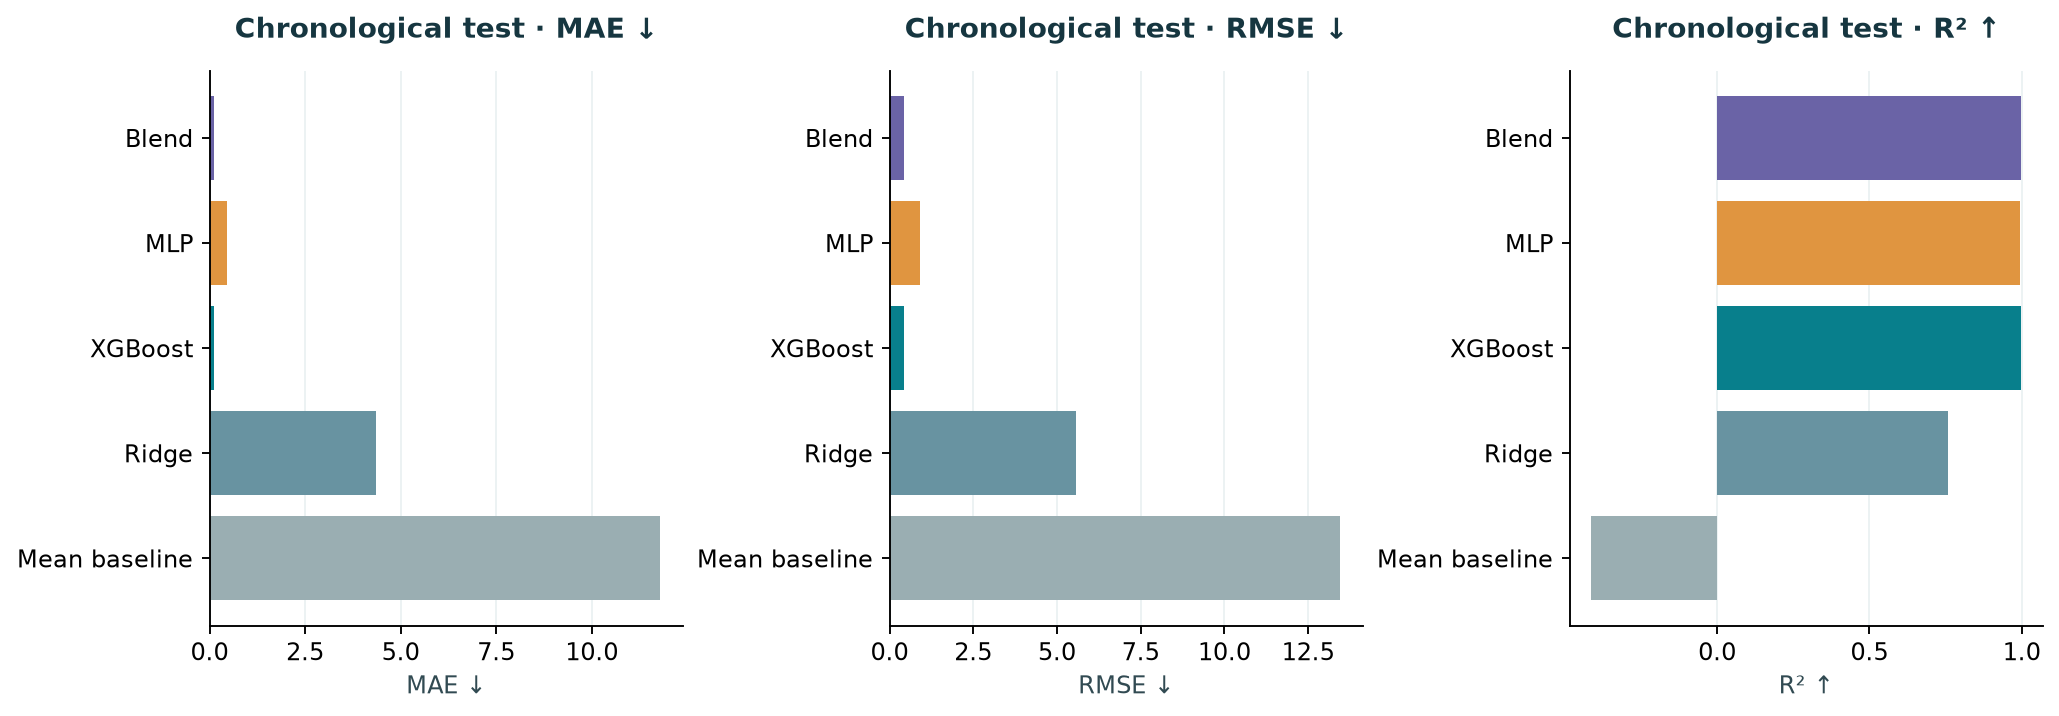

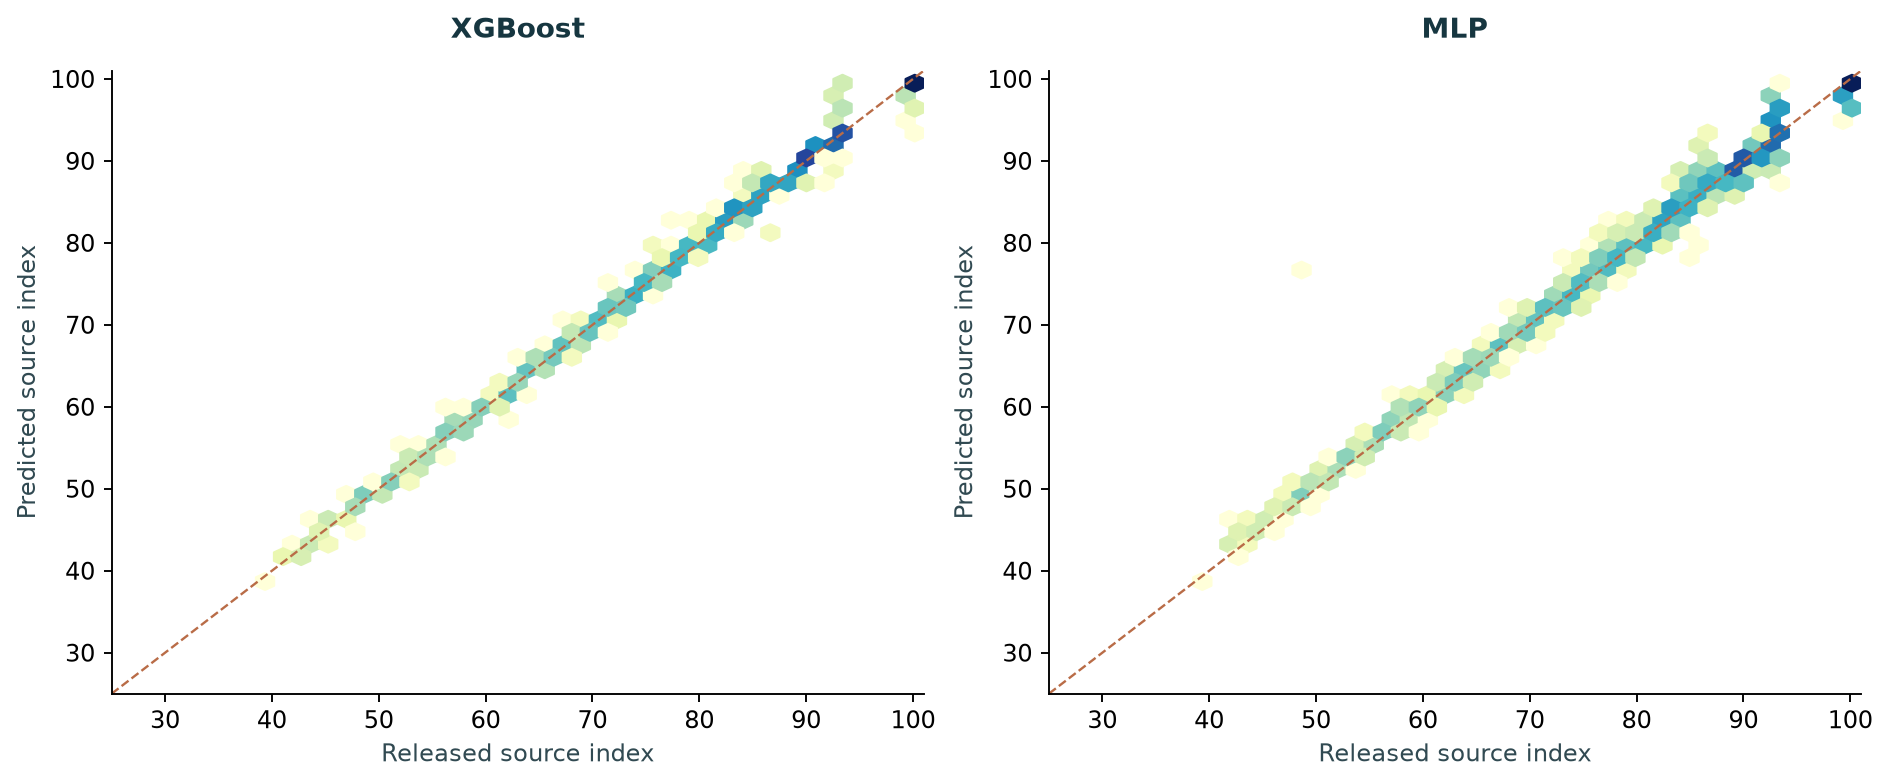

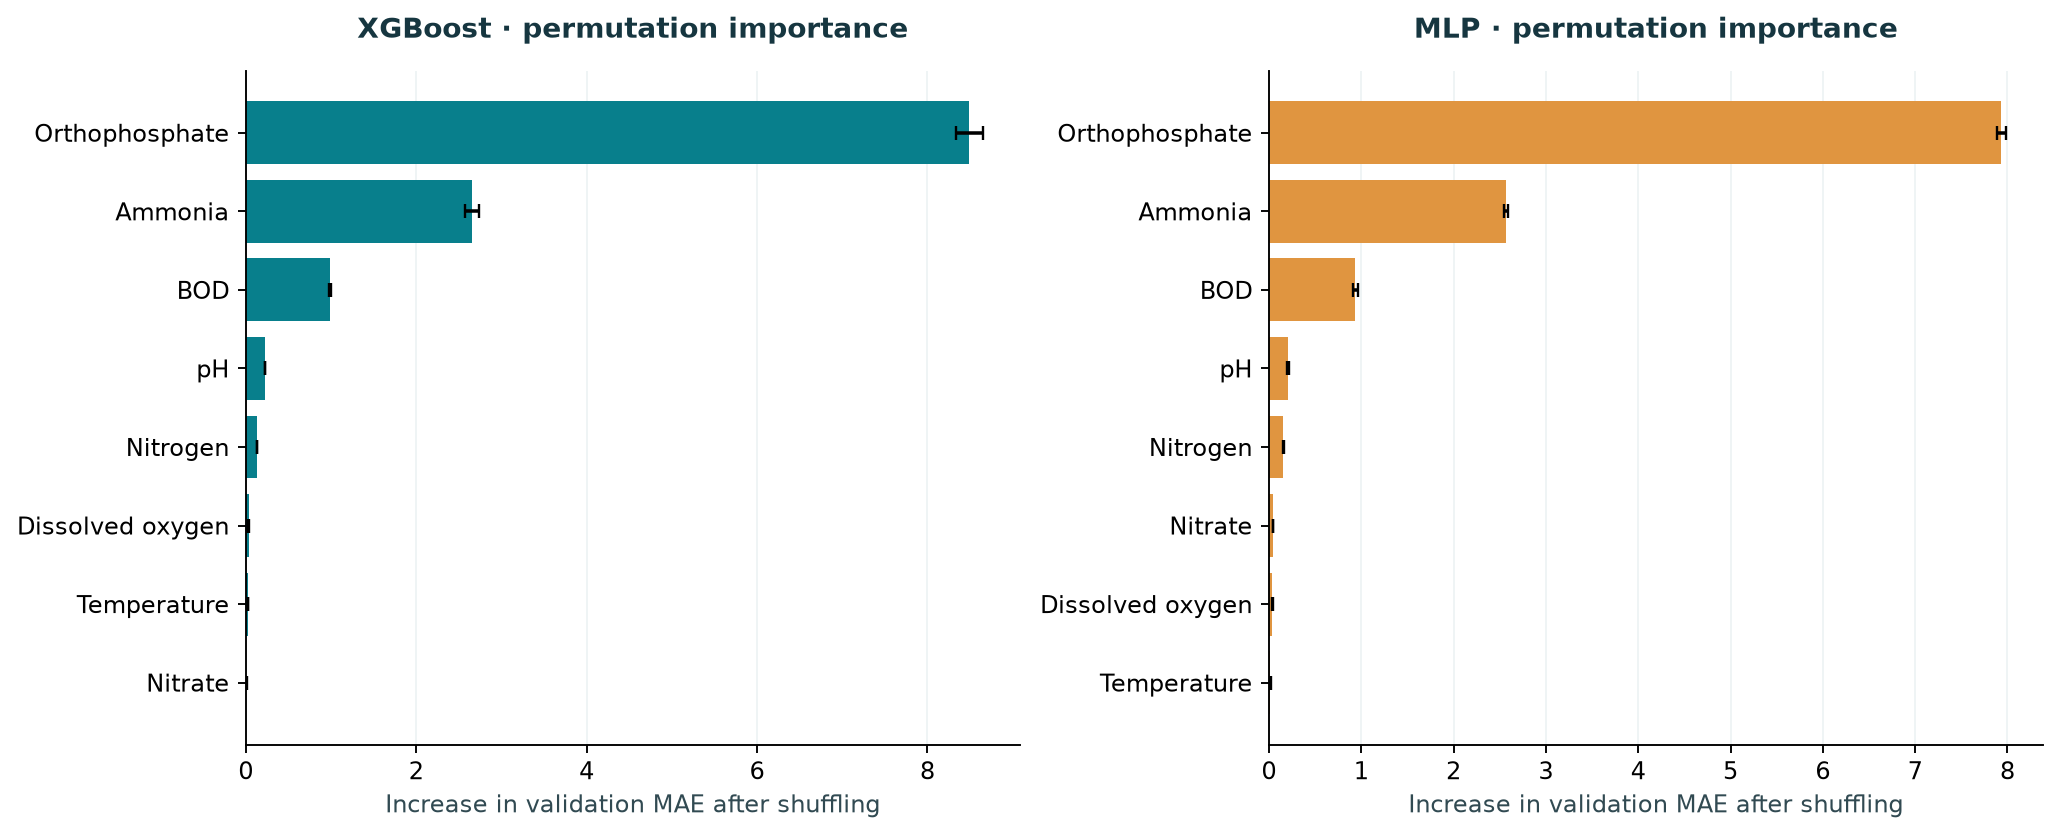

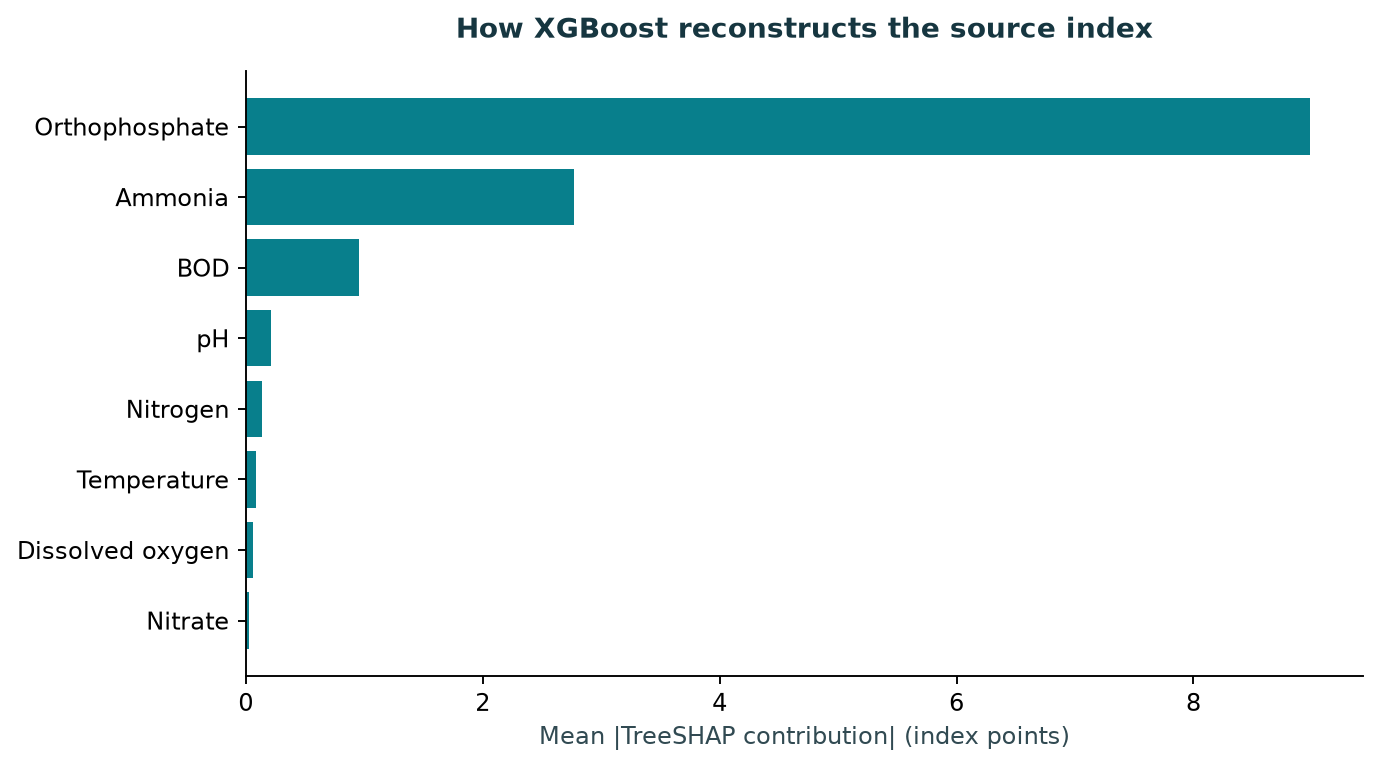

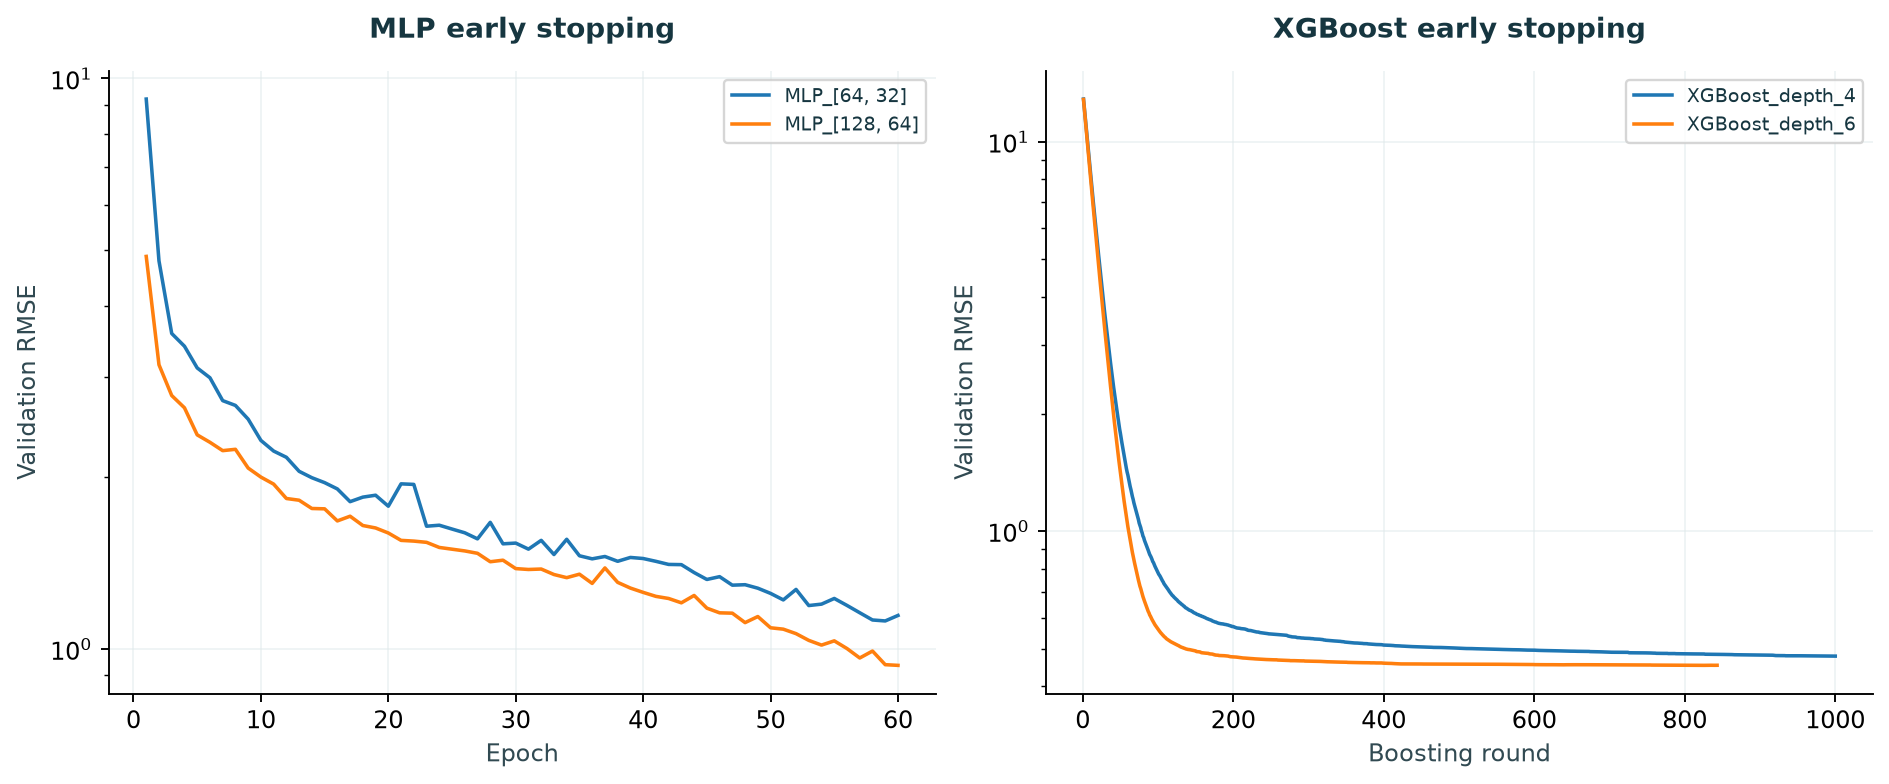

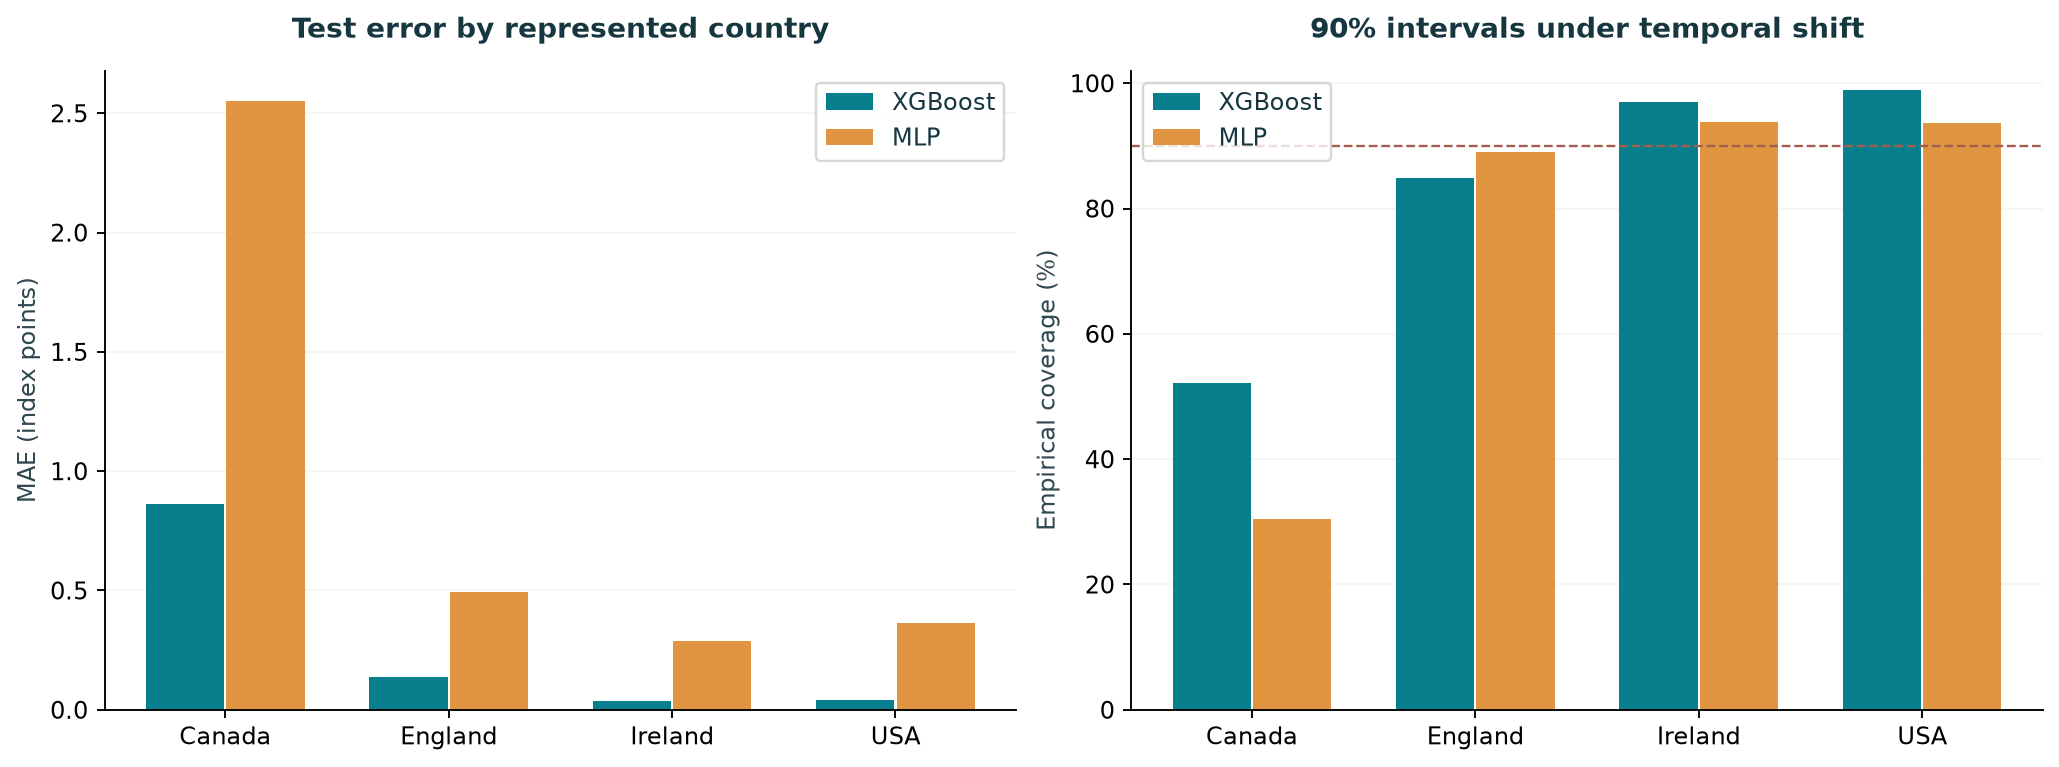

In [11]:
if RETRAIN:
    create_figures(out, audit, manifest, scores, groups, importance, shap_table, histories, prediction_table)
    # One reference-style archive contains all trained models and measured tables.
    # Intermediate preparation data are deliberately excluded.
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED, compresslevel=6) as z:
        for folder in [out, artifacts]:
            for file in sorted(folder.rglob("*")):
                if file.is_file(): z.write(file, file.relative_to(WORK))
    print(f"Saved {archive.name} ({archive.stat().st_size / 1024**2:.1f} MiB)")

scores = pd.read_csv(out / "metrics.csv")
display(scores[["model", "mae", "rmse", "r2", "coverage", "mean_width", "validation_rmse"]].round(5))
for name in ["model_comparison.png", "actual_vs_predicted.png", "feature_importance.png", "shap_importance.png", "learning_curves.png", "country_performance.png"]:
    display(Image(filename=str(FIGURES / name)))

## 10. Predict using reloaded models
This cell demonstrates actual model loading and prediction, including quality flags and residual intervals. The five example rows come from the held-out test set. Reloaded results are checked against saved predictions. For a new CSV, use the commented example at the end.

In [12]:
metadata = json.loads((artifacts / "metadata.json").read_text())
checksums = json.loads((artifacts / "checksums.json").read_text())
for filename, expected in checksums.items():
    assert sha256(artifacts / filename) == expected, f"Changed model file: {filename}"
preprocessors = joblib.load(artifacts / "preprocessing.joblib")
xgb_saved = XGBRegressor()
xgb_saved.load_model(artifacts / "xgboost.json")
mlp_saved = MLP(16, metadata["mlp_widths"], metadata["dropout"])
mlp_saved.load_state_dict(torch.load(artifacts / "mlp.pt", map_location="cpu", weights_only=True))
mlp_saved.eval()

def predict_measurements(frame):
    """Input headers/units must match the dataset; output is the source index."""
    features = quality_features(frame)
    px = np.clip(xgb_saved.predict(preprocessors["tree"].transform(features)), 0, 100)
    pn = predict_mlp(mlp_saved, preprocessors["neural"].transform(features).astype("float32"))
    w = metadata["blend_xgboost_weight"]
    blended = w*px + (1-w)*pn
    outputs = {"XGBoost": px, "MLP": pn, "Blend": blended}
    selected = outputs[metadata["selected_model"]]
    low, high = intervals(selected, metadata["radii"][metadata["selected_model"]])
    return pd.DataFrame({**outputs, "selected_lower_90": low, "selected_upper_90": high,
                         "flagged_inputs": features.iloc[:, 8:].sum(axis=1).to_numpy()}, index=frame.index)

example = pd.read_csv(out / "Example/measurements.csv")
expected = pd.read_csv(out / "Example/expected_predictions.csv")
result = predict_measurements(example)
display(pd.concat([example, result], axis=1))
for name in ["XGBoost", "MLP", "Blend", "selected_lower_90", "selected_upper_90"]:
    np.testing.assert_allclose(result[name], expected[name], rtol=0, atol=1e-5)
print("Reloaded-model predictions match the saved holdout examples.")
# For your own measurements, preserve the eight exact column headers and units:
# new_readings = pd.read_csv("your_measurements.csv")
# predict_measurements(new_readings)

Reloaded-model predictions match the saved holdout examples.


,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),XGBoost,MLP,Blend,selected_lower_90,selected_upper_90,flagged_inputs
0,0.098000,2.7,9.040000,0.144000,7.95,14.0000,5.00,4.500,89.641640,89.660439,89.643517,89.390137,89.896896,0.0
1,0.030000,2.7,10.200000,0.010000,7.78,9.4000,0.71,0.706,99.999184,100.000000,99.999260,99.745880,100.000000,0.0
2,0.062000,2.7,8.830000,0.290000,7.81,16.4000,1.80,1.770,81.948250,82.223930,81.975815,81.722435,82.229195,0.0
3,0.500000,2.7,10.200000,0.700000,7.78,11.4600,18.00,4.500,69.281456,67.800247,69.133331,68.879951,69.386711,0.0
4,0.016667,1.4,11.684103,0.019625,8.00,8.1375,0.22,1.300,99.996292,100.000000,99.996658,99.743279,100.000000,0.0


## Interpretation and limitations
XGBoost is the stronger individual model. The selected 90% XGBoost / 10% MLP blend slightly reduces RMSE while worsening MAE. One seed and two candidates per family do not establish a statistically significant advantage. The selected MLP reaches the 60-epoch budget, so full convergence is unproven.

All released labels reconstruct from the same eight inputs. High R² therefore establishes index emulation. The transparent formula is preferable when all original components are available. A meaningful extension needs independent outcomes, withheld sensors or a properly defined site-period index.

Upstream imputation and uncertain unit conversion cannot be undone. England dominates the data. About 85.9% of test rows come from historical sites. China has no test rows and Canada has only 46. Overall interval coverage hides poor coverage in some index bands. The model makes no drinking-water safety decision.

Sources: [Figshare dataset](https://doi.org/10.6084/m9.figshare.27800394.v2), [CCME manual](https://ccme.ca/en/res/wqimanualen.pdf), [XGBoost](https://doi.org/10.1145/2939672.2939785), [Deep Learning, chapter 6](https://www.deeplearningbook.org/contents/mlp.html), [Conformal prediction](https://arxiv.org/abs/2107.07511).